# Homework 5 — Gravitational-Wave Course

## Exercise 3 — Method of Lines

To solve this problem, we will reuse the finite-difference and fourth-order Runge–Kutta (RK4) methods implemented in the previous two exercises. The method of lines allows us to discretize the spatial derivative, reducing the partial differential equation (PDE) to a system of ordinary differential equations (ODEs), which can then be evolved in time using RK4.

In [ ]:
#libraries
import numpy as np
import matplotlib.pyplot as plt

print("Environment ready!")

Environment ready!


# Section: Finite Differences

### 4th-Order Finite Differences

In Exercise 1, we implemented a 4th-order centered finite-difference method to approximate the first spatial derivative. This approximation uses the function values at two neighboring points on each side of the evaluation point:

$$
\left.\frac{df}{dx}\right|_{x_i}
\simeq
\frac{
f_{i-2}-8f_{i-1}+8f_{i+1}-f_{i+2}
}{12\Delta x}.
$$

Since this stencil requires two additional points on either side of the computational domain, we introduced **ghost points** to evaluate the derivative near the boundaries.

For the present exercise, however, we need to compute spatial derivatives at every grid point in order to construct the system of ordinary differential equations associated with the method of lines. The **treatment of the boundaries** is therefore particularly important.

To avoid evaluating the solution outside the computational domain, we **introduce a second finite-difference operator,** which combines three different stencils:

- **Forward differences:** used at the first two grid points.
- **Centered differences:** used at the interior points.
- **Backward differences:** used at the last two grid points.

The forward and backward stencils provide fourth-order approximations at the boundaries without requiring ghost points. The centered stencil is the same one used in Exercise 1.

Both implementations achieve fourth-order spatial accuracy, but they differ in how the boundary points are treated.

For the advection equation considered here, we will use the one-sided implementation to calculate the spatial derivative throughout the computational domain. This allows us to handle the boundary points without introducing additional values outside the grid, consistently with the boundary conditions specified in the problem.

In [ ]:
# Ghost points:

def finite_difference_4th(f, dx, ghost_left, ghost_right):

    f = np.asarray(f, dtype=float)

 # Extend the grid with two ghost points on each side
    f_extended = np.concatenate([
        ghost_left,
        f,
        ghost_right
    ])

    df_dx = np.zeros_like(f)

     # Apply the fourth-order centered finite-difference stencil

    for i in range(len(f)):

        j = i + 2

        df_dx[i] = (
            f_extended[j-2]
            - 8*f_extended[j-1]
            + 8*f_extended[j+1]
            - f_extended[j+2]
        ) / (12*dx)

    return df_dx


# Function with one-sided stencils (NEW)

def finite_difference_4th_onesided(f, dx):

    f = np.asarray(f, dtype=float)

    N = len(f)

    if N < 5:
        raise ValueError("At least 5 points are required.")

    df = np.zeros_like(f)


    # Forward fourth-order stencil at the left boundary
    for i in range(2):

        df[i] = (
            -25*f[i]
            + 48*f[i+1]
            - 36*f[i+2]
            + 16*f[i+3]
            - 3*f[i+4]
        ) / (12*dx)

    # Centered fourth-order stencil at interior points
    for i in range(2, N-2):

        df[i] = (
            f[i-2]
            - 8*f[i-1]
            + 8*f[i+1]
            - f[i+2]
        ) / (12*dx)

    # Backward fourth-order stencil at the right boundary
    for i in range(N-2, N):

        df[i] = (
            25*f[i]
            - 48*f[i-1]
            + 36*f[i-2]
            - 16*f[i-3]
            + 3*f[i-4]
        ) / (12*dx)

    return df

print("Stage 1 functions loaded!")

Stage 1 functions loaded!


# Section: Runge-Kutta 4th order

### 4th-O. Runge–Kutta Method

We reuse the RK4 integrator implemented and validated in Exercise 2.

Previously, RK4 was applied to the harmonic oscillator, where the state vector contained position and velocity. In the present exercise, the state vector contains the values of the solution at all spatial grid points:

$$
\mathbf{u}(t)=
\begin{pmatrix}
u(t,x_0)\\
u(t,x_1)\\
\vdots\\
u(t,x_{N-1})
\end{pmatrix}.
$$

After discretizing the spatial derivative, the advection equation becomes a system of ordinary differential equations of the form

$$
\frac{d\mathbf{u}}{dt}=\mathbf{F}(\mathbf{u},t).
$$

The same RK4 function can then evolve the entire spatial profile in time. No changes to the integration algorithm are required; only the right-hand-side function $\mathbf{F}$ must be defined for the advection equation.

In [ ]:
def rk4(F, u, t, dt):

    u = np.asarray(u, dtype=float)

    k1 = np.asarray(F(u, t), dtype=float)

    k2 = np.asarray(
        F(u + 0.5*dt*k1, t + 0.5*dt),
        dtype=float
    )

    k3 = np.asarray(
        F(u + 0.5*dt*k2, t + 0.5*dt),
        dtype=float
    )

    k4 = np.asarray(
        F(u + dt*k3, t + dt),
        dtype=float
    )

    u_next = u + (dt/6.0)*(k1 + 2*k2 + 2*k3 + k4)

    return u_next

print("Stage 2 functions loaded!")

Stage 2 functions loaded!


# Replace Advection RHS evolution equation


### Spatial Discretization: Advection Equation

We now construct the right-hand side of the semi-discrete system associated with the advection equation

$$
\partial_t u(t,x)=-\partial_x u(t,x).
$$

After discretizing the spatial domain, each grid point becomes a time-dependent variable. Therefore, the PDE is transformed into a system of ordinary differential equations:

$$
\frac{du_i}{dt}=-\left.\frac{\partial u}{\partial x}\right|_{x_i}.
$$

We approximate the spatial derivative using 4th-finite differences, adapting the stencil to the different regions of the computational domain:

**Left boundary**

The Dirichlet boundary condition requires the solution to vanish at the left boundary:

$$
u(t,x_L)=0.
$$

Consequently, we set

$$
\frac{du_0}{dt}=0.
$$

**First interior point**

At the first interior point, the centered stencil requires a value outside the computational domain. We introduce an odd ghost-point extension:

$$
u_{-1}=-u_1,
\qquad u_0=0.
$$

Substituting these values into the centered stencil gives

$$
\frac{du_1}{dt}
\simeq
\frac{u_1-8u_2+u_3}{12\Delta x}.
$$

**Interior points**

For the remaining interior points, we use the centered 4th-order stencil:

$$
\frac{du_i}{dt}
\simeq
\frac{-u_{i-2}+8u_{i-1}-8u_{i+1}+u_{i+2}}
{12\Delta x}.
$$

**Right boundary**

At the right boundary, the characteristics are outgoing, so no additional boundary condition is imposed. Instead, we use a 4th-order backward finite-difference stencil:

$$
\frac{du_i}{dt}
\simeq
\frac{
-25u_i+48u_{i-1}-36u_{i-2}
+16u_{i-3}-3u_{i-4}
}{12\Delta x}.
$$

Combining these expressions defines the function $\mathbf{F}(\mathbf{u},t)$ required by the RK4 integrator.

In [ ]:

# 4th-finite difference discretization

def advection_rhs(u, t, dx):

    N = len(u)

    dudt = np.zeros_like(u)


    # Left boundary: Dirichlet condition

    dudt[0] = 0.0


    # First interior point: use an odd ghost-point extension to enforce the homogeneous Dirichlet condition at the left boundary:
    # u[-1] = -u[1], since u[0] = 0.

    dudt[1] = (          # Use an odd extension of the solution at the left boundary: employ a ghost point with u_{-1}=-u_1, along with u_0=0.
        u[1]
        - 8*u[2]
        + u[3]
    ) / (12*dx)

    # Interior: centered fourth-order stencil


    dudt[2:N-2] = (
        -u[0:N-4]
        + 8*u[1:N-3]
        - 8*u[3:N-1]
        + u[4:N]
    ) / (12*dx)


    # Right boundary: backward fourth-order stencil


    for i in range(N-2, N):

        dudt[i] = (
            -25*u[i]
            + 48*u[i-1]
            - 36*u[i-2]
            + 16*u[i-3]
            - 3*u[i-4]
        ) / (12*dx)

    return dudt

# Computing the Grid and Time Discretization


### Spatial and Temporal Discretization

We discretize the spatial domain $[r_L,r_R]=[0,10]$ using a uniform grid with spacing $\Delta x=0.01$, resulting in 1001 spatial points.

The time evolution is performed over the interval $t\in[0,10]$, with a time step $\Delta t=0.005$ and 2000 time steps.

Our choice of time step satisfies

$$
\Delta t=0.5\Delta x,
$$

as suggested in the exercise for numerical stability.


In [ ]:
# Spatial domain
r_L = 0.0
r_R = 10.0

# Spatial resolution
dx = 0.01

# Number of spatial points
N = int((r_R - r_L)/dx) + 1

# Spatial grid
x = np.linspace(r_L, r_R, N)

# Actual grid spacing
dx = x[1] - x[0]


# Temporal domain


t_initial = 0.0
t_final = 10.0

# Time step
dt = 0.005

# Number of time steps
N_t = int((t_final - t_initial)/dt)

# Time grid
t = np.linspace(
    t_initial,
    t_final,
    N_t + 1
)



# Grid information


print("Spatial domain:", r_L, "to", r_R)
print("Spatial resolution:", dx)
print("Number of spatial points:", N)

print("Time interval:", t_initial, "to", t_final)
print("Time step:", dt)
print("Number of time steps:", N_t)

Spatial domain: 0.0 to 10.0
Spatial resolution: 0.01
Number of spatial points: 1001
Time interval: 0.0 to 10.0
Time step: 0.005
Number of time steps: 2000


# Initial Gaussian Profile

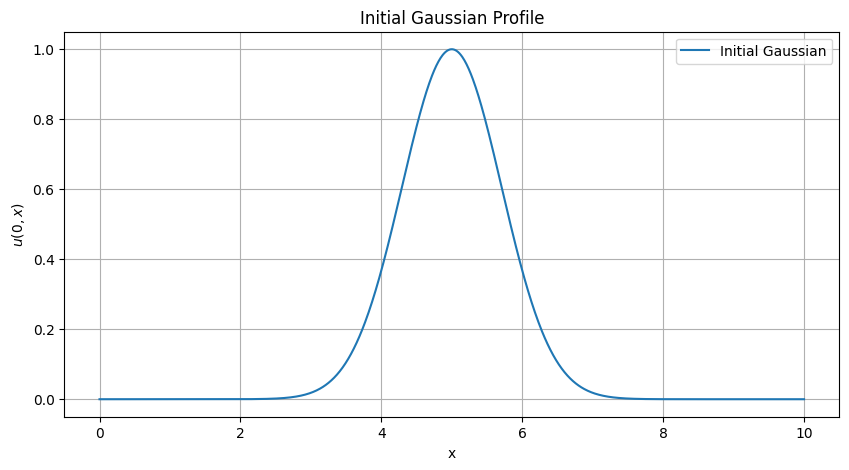

In [ ]:

# Gaussian center
x0 = 5.0

# Initial Gaussian profile
u_initial = np.exp(-(x - x0)**2)

# Impose left boundary condition
u_initial[0] = 0.0



# Plot initial condition


plt.figure(figsize=(10, 5))

plt.plot(x, u_initial, label="Initial Gaussian")

plt.xlabel("x")
plt.ylabel(r"$u(0,x)$")

plt.title("Initial Gaussian Profile")

plt.legend()
plt.grid()

plt.show()

# Method of Lines evolution (implementing RK4 for time evolution)

In [ ]:

# Allocate solution array
u = np.zeros((N_t + 1, N))

# Initial condition
u[0, :] = u_initial.copy()

# Snapshot times
snapshot_times = [0, 2, 4, 6, 8, 10]

snapshots = {}

snapshots[0] = u_initial.copy()

# Maximum amplitude during evolution
#Useful for detecting potential, unwanted numerical growth during the evolution.
max_amplitude = np.zeros(N_t + 1)

max_amplitude[0] = np.max(np.abs(u_initial))




# METHOD OF LINES - TIME EVOLUTION


for n in range(N_t):

    # One RK4 time step
    u[n+1, :] = rk4(
        lambda state, time: advection_rhs(state, time, dx),
        u[n, :],
        t[n],
        dt
    )

    # Enforce left boundary condition
    u[n+1, 0] = 0.0

    # Monitor amplitude
    max_amplitude[n+1] = np.max(
        np.abs(u[n+1, :])
    )

    # Save snapshots
    if np.any(np.isclose(t[n+1], snapshot_times)):
        snapshots[round(t[n+1])] = u[n+1, :].copy()


print("Evolution completed!")
print("Final time:", t[-1])
print("Maximum amplitude:", np.max(max_amplitude))
print("All values finite:", np.all(np.isfinite(u)))

Evolution completed!
Final time: 10.0
Maximum amplitude: 1.0000000000273421
All values finite: True



### Explanation:
Method of Lines: Time Evolution

After discretizing the spatial derivative, the advection equation becomes a system of coupled ordinary differential equations:

$$
\frac{d\mathbf{u}}{dt}=\mathbf{F}(\mathbf{u},t),
$$

where $\mathbf{u}(t)$ contains the solution at all spatial grid points, and $\mathbf{F}$ is determined by the 4th-order finite difference approximation.

We integrate this system in time using the 4th-order Runge-Kutta method (RK4). Starting from the initial Gaussian profile, we evolve the solution from $t=0$ to $t=10$.

During the evolution, we:
- Enforce the left Dirichlet boundary condition, $u(t,0)=0$.
- Store the solution at selected times for later visualization.
- Monitor the maximum absolute amplitude to check for possible numerical growth.

The evolution completes successfully. The maximum amplitude remains approximately equal to its initial value, and all computed values are finite.


# Evolution snapshots

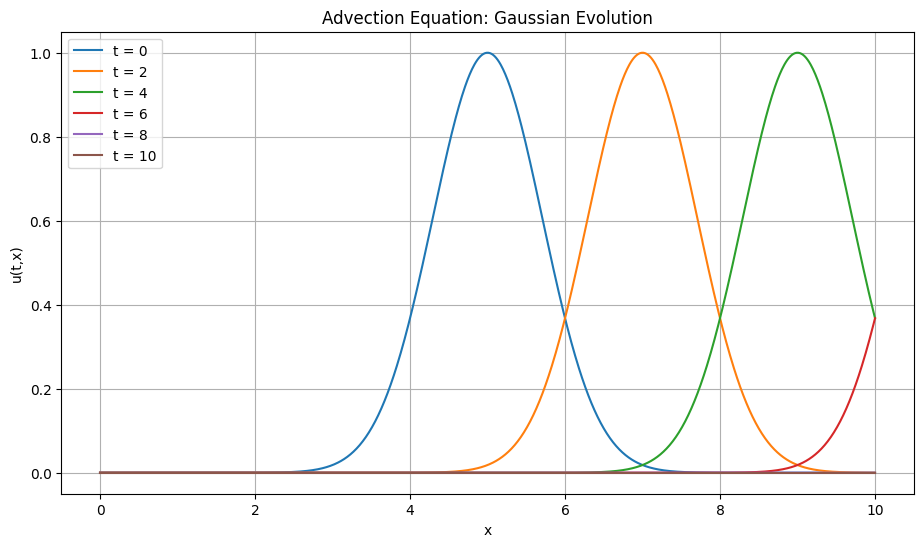

In [ ]:

# Gaussioan propagation

plt.figure(figsize=(11,6))

for time in snapshot_times:

    plt.plot(
        x,
        snapshots[time],
        label=f"t = {time}"
    )

plt.xlabel("x")
plt.ylabel("u(t,x)")

plt.title("Advection Equation: Gaussian Evolution")

plt.legend()
plt.grid()

plt.show()


### Explanation: Evolution of the Gaussian Profile (graph above)

The snapshots show the propagation of the initial Gaussian profile towards the right boundary.

For the advection equation

$$
\partial_t u=-\partial_x u,
$$

the analytical solution on an infinite domain is

$$
u(t,x)=e^{-(x-x_0-t)^2},
$$

so the Gaussian travels with unit speed while preserving its shape.

As the profile approaches the right boundary, it progressively leaves the computational domain $[0,10]$. Consequently, its amplitude inside the domain decreases at later times.


# Comparison with the analytical solution

In [ ]:

# Analytical solution at final time
u_exact = np.exp(-(x - x0 - t[-1])**2)

# Impose left boundary condition
u_exact[0] = 0.0

# Numerical solution

u_numerical = u[-1, :]

# Absolute error
error = np.abs(u_exact - u_numerical)

print("Maximum absolute error:", np.max(error))
print("L2 error:", np.sqrt(dx * np.sum(error**2)))

Maximum absolute error: 5.649544847039181e-11
L2 error: 5.533575953082665e-11


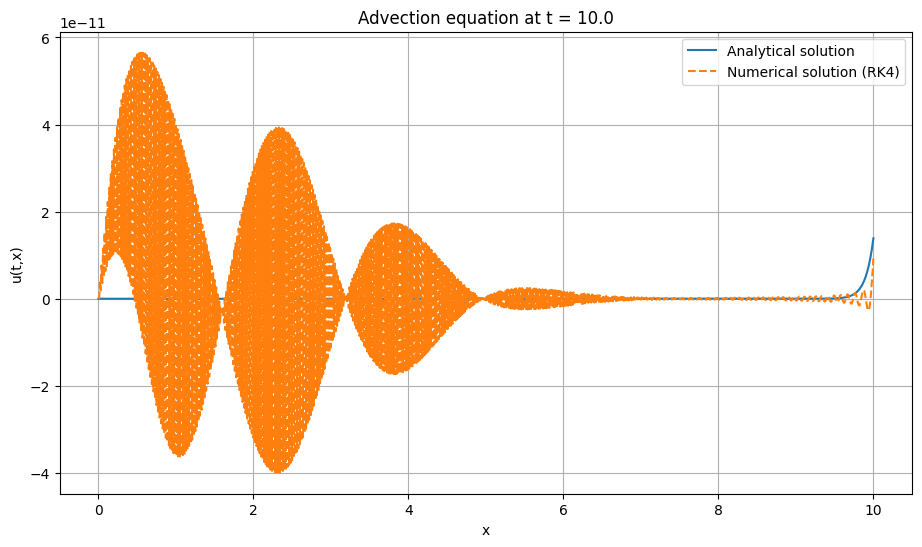

In [ ]:
#Plotting both solutions
plt.figure(figsize=(11, 6))

plt.plot(x, u_exact, label="Analytical solution")

plt.plot(
    x,
    u_numerical,
    "--",
    label="Numerical solution (RK4)"
)

plt.xlabel("x")
plt.ylabel("u(t,x)")
plt.title(f"Advection equation at t = {t[-1]}")

plt.legend()
plt.grid()

plt.show()

Comparison time: 2.0
Maximum analytical amplitude: 1.0
Maximum absolute error: 2.214492855756589e-08
L2 error: 2.3298426866237776e-08


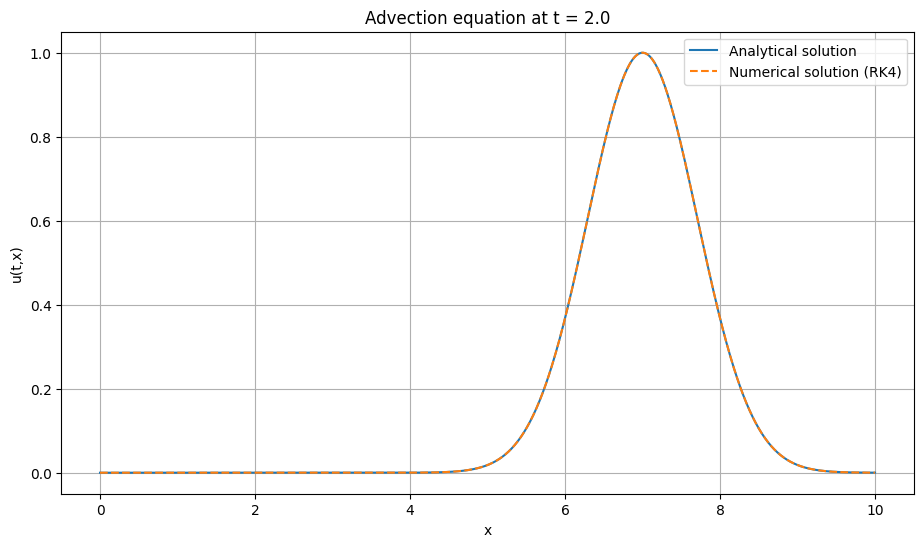

In [ ]:

# Comparison at an intermediate time


# Select comparison time
t_check = 2.0

# Find corresponding numerical time index
n_check = np.argmin(np.abs(t - t_check))

# Actual numerical time
t_actual = t[n_check]

# Numerical solution
u_num_check = u[n_check, :]

# Analytical solution
u_exact_check = np.exp(-(x - x0 - t_actual)**2)

# Impose left boundary condition
u_exact_check[0] = 0.0

# Absolute error
error_check = np.abs(u_exact_check - u_num_check)

print("Comparison time:", t_actual)
print("Maximum analytical amplitude:", np.max(np.abs(u_exact_check)))
print("Maximum absolute error:", np.max(error_check))
print("L2 error:", np.sqrt(dx*np.sum(error_check**2)))

# Plot
plt.figure(figsize=(11,6))

plt.plot(x, u_exact_check, label="Analytical solution")

plt.plot(
    x,
    u_num_check,
    "--",
    label="Numerical solution (RK4)"
)

plt.xlabel("x")
plt.ylabel("u(t,x)")
plt.title(f"Advection equation at t = {t_actual}")

plt.legend()
plt.grid()
plt.show()


### Explanation of the graph above.

Comparison with the Analytical Solution at an Intermediate Time

To assess the accuracy of the numerical evolution, we compare the RK4 solution with the analytical solution at $t=2$.

For the advection equation, the analytical solution is

$$
u(t,x)=e^{-(x-x_0-t)^2}.
$$

At this intermediate time, the Gaussian profile is still well contained within the computational domain. This allows us to compare the numerical and analytical solutions without significant effects from the right boundary.

The two curves overlap almost perfectly, showing that the numerical method accurately reproduces the propagation of the initial profile.


# Convergence analysis


### Convergence Analysis

To investigate the convergence of the method of lines, we repeat the numerical evolution using progressively finer spatial grids.

We consider four different spatial resolutions,

$$
\Delta x = 0.08,\;0.04,\;0.02,\;0.01.
$$

For each spatial resolution, we choose the time step according to

$$
\Delta t = C_{\mathrm{CFL}}\,\Delta x,
$$

where $C_{\mathrm{CFL}}$ is a constant factor relating the temporal and spatial resolutions. In our implementation, we set

$$
C_{\mathrm{CFL}}=0.5,
$$

so that

$$
\Delta t=0.5\,\Delta x.
$$

This choice follows the recommendation in the exercise, which states that the time step should be smaller than the spatial grid spacing and gives $\Delta t=0.5\Delta r$ as a common choice for stability.

For each resolution, we evolve the initial Gaussian profile up to $t=2$ and calculate the maximum absolute error with respect to the analytical solution,

$$
E(\Delta x)=
\max_i\left|
u_{\mathrm{exact}}(t,x_i)
-
u_{\mathrm{numerical}}(t,x_i)
\right|.
$$

We then use the resulting errors to estimate the numerical convergence order and verify whether the method exhibits the expected fourth-order accuracy.



In [ ]:


dx_values = [0.08, 0.04, 0.02, 0.01]

errors = []

t_final_conv = 2.0
CFL = 0.5

for dx_test in dx_values:

    # Grid
    x_test = np.arange(0, 10 + dx_test/2, dx_test)

    # Time step
    dt_test = CFL * dx_test

    N_t_test = int(round(t_final_conv / dt_test))

    dt_test = t_final_conv / N_t_test

    t_test = np.linspace(0, t_final_conv, N_t_test + 1)

    # Initial condition
    u_test = np.exp(-(x_test - x0)**2)

    # Impose left boundary
    u_test[0] = 0.0

    # Time evolution
    for n in range(N_t_test):

        u_test = rk4(
            lambda state, time: advection_rhs(
                state, time, dx_test
            ),
            u_test,
            t_test[n],
            dt_test
        )

        # Left boundary condition
        u_test[0] = 0.0

    # Analytical solution
    u_exact_test = np.exp(
        -(x_test - x0 - t_final_conv)**2
    )

    u_exact_test[0] = 0.0

    # Maximum error
    error = np.max(np.abs(u_exact_test - u_test))

    errors.append(error)

    print(
        f"dx = {dx_test:.4f} | "
        f"dt = {dt_test:.5f} | "
        f"Error = {error:.8e}"
    )

dx = 0.0800 | dt = 0.04000 | Error = 8.99424772e-05
dx = 0.0400 | dt = 0.02000 | Error = 5.65727591e-06
dx = 0.0200 | dt = 0.01000 | Error = 3.54169854e-07
dx = 0.0100 | dt = 0.00500 | Error = 2.21449286e-08


In [ ]:
#Convergence Order

print("CONVERGENCE ORDER")

for i in range(len(errors)-1):

    p = np.log(errors[i]/errors[i+1]) / np.log(
        dx_values[i]/dx_values[i+1]
    )

    print(f"Order: {p:.4f}")

CONVERGENCE ORDER
Order: 3.9908
Order: 3.9976
Order: 3.9994


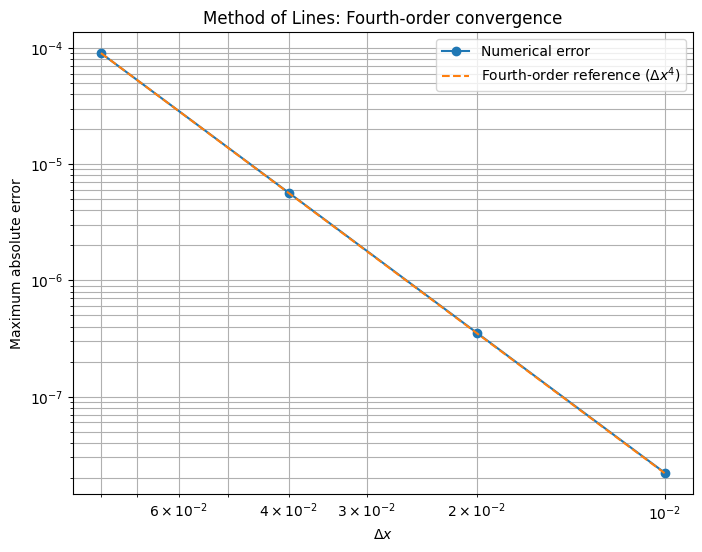

In [ ]:
# Convergence plotting

plt.figure(figsize=(8,6))

plt.loglog(
    dx_values,
    errors,
    'o-',
    label="Numerical error"
)

# Fourth-order reference
reference = errors[0] * (
    np.array(dx_values)/dx_values[0]
)**4

plt.loglog(
    dx_values,
    reference,
    '--',
    label=r"Fourth-order reference ($\Delta x^4$)"
)

plt.xlabel(r"$\Delta x$")
plt.ylabel("Maximum absolute error")

plt.title("Method of Lines: Fourth-order convergence")

plt.legend()
plt.grid(True, which="both")

plt.gca().invert_xaxis()

plt.show()

In [ ]:
# Stability

print("Maximum absolute value:",
      np.max(np.abs(u)))

print("All values finite:",
      np.all(np.isfinite(u)))

print("Final profile maximum:",
      np.max(np.abs(u[-1])))

Maximum absolute value: 1.0000000000273421
All values finite: True
Final profile maximum: 5.649544847039181e-11



## Conclusion

In this exercise, we implemented the** method of lines** to solve the one-dimensional advection equation,

$$
\partial_t u(t,x)=-\partial_x u(t,x),
$$

by combining a 4th-order finite difference discretization in space with the 4th-order Runge-Kutta method for time integration.
**bold text**
The numerical evolution reproduces the propagation of the initial Gaussian profile with excellent agreement with the analytical solution. The comparison at intermediate times confirms that the profile propagates in the positive $x$-direction while approximately preserving its shape and amplitude.

The convergence analysis provides further evidence of the accuracy of the implementation. By refining the spatial and temporal resolutions simultaneously while keeping the CFL number fixed, we obtain numerical convergence orders approaching

$$
p=4.
$$

This agrees with the expected fourth-order accuracy of both the spatial discretization and the time integration scheme.

Finally, the stability checks show that all numerical values remain finite and that no spurious growth in the solution amplitude occurs during the evolution.

Overall, the results demonstrate that the method of lines, together with fourth-order finite differences and RK4, provides an accurate numerical solution to the one-dimensional advection equation.
